# NB\_C01: The Digital Twin Concept and Data Landscape

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/glioma-brain-digital-twin-public/blob/main/notebooks/NB_C01_Digital_Twin_Concept_and_Data.ipynb)

**Capstone Notebook Series** -- Glioma Brain Digital Twin Project  
**Workshop:** Mathematical Challenges in Brain Mechanics ([CAS 2025/2026](https://cas-nor.no/project/mathematical-challenges-brain-mechanics)), 9-11 March 2026, Hotel Finse 1222 [[link](https://cas-nor.no/events/mathematical-challenges-brain-mechanics-workshop)]  
**Patient:** sub-PAT16 (anaplastic astrocytoma WHO II--III, fronto-temporal) from the OpenNeuro repository [[preop](https://openneuro.org/datasets/ds001226/versions/5.0.0)] [[postop](https://openneuro.org/datasets/ds002080/versions/4.0.0)]<br>
**Date:** 7 March 2026 <br>
**Creator:** Arvid Lundervold w/ Cursor 2.6.12 and Opus 4.6

---

## Objectives

- Understand what a digital twin is and why glioma patients are uniquely suited for this approach
- Identify the mathematical challenges in building a brain digital twin
- Survey the multimodal data collected from a single patient at two timepoints
- Visualise the data landscape and processing pipeline

**Prerequisites:** None (this is the entry point of the capstone series)  
**Next:** [NB\_C02](NB_C02_Clinical_Cognitive_Data.ipynb) (clinical and cognitive data)

<!--
Run each notebook in order locally (where Freeview is available), fix any issues as they surface, and capture what you need for the slides along the way.

A practical sequence:

NB_C01 and NB_C02 first -- these are pure metadata/figures with no heavy data dependencies. Quick to validate, and the figures (coupling chain schematic, data landscape, CANTAB radar plots) are likely slide candidates.

NB_C03 -- structural MRI and segmentation. Run it, check the T1w/lesion/parcellation overlays. Then use Freeview interactively to find the best axial/coronal/sagittal views for the slides -- these anatomical context shots are hard to get right programmatically.

NB_C04 -- diffusion MRI. The DTI scalar maps (FA, MD) and SC matrices. Freeview with freeview_dti.sh for tractography overlays if you want fibre tract snapshots.

NB_C05 -- rs-fMRI. The rsHRF maps and FC matrices. Use freeview_all.sh for BOLD time-course screenshots.

NB_C06 -- brain mechanics. The FEM displacement vs empirical displacement comparison is a key slide. Freeview for displacement magnitude overlays.

NB_C07 and NB_C08 -- neural dynamics and closing the loop. These produce the coupling results and the predicted-vs-observed quadrant plot. Core results for the talk.

NB_C09 -- synthesis. Mostly text and summary tables. Quick pass.

For the Freeview captures specifically: use Freeview's File > Save Screenshot (or Cmd+S in the viewer) at the exact slice/orientation you want. Save them into figures/capstone/ with descriptive names (e.g., figC03_freeview_tumor_axial.png) so they're easy to reference when building the Beamer/Google Slides deck.

Cursor help refine any specific notebook as we work through them -- fixing figure aesthetics, adjusting colormaps, adding annotations, or anything else that comes up.
-->

---
## 1. What Is a Digital Twin?

A **digital twin** is a computational replica of a physical system that is
continuously updated with real-world data and used for simulation,
prediction, and decision support.

The concept originated in aerospace engineering (NASA, 2010s) and industrial
manufacturing (GE, Siemens), where digital twins of jet engines, turbines,
and production lines are used to predict failures, optimise maintenance
schedules, and test design changes *in silico* before committing to costly
physical experiments.

### From Engineering to Medicine

The translation to biomedicine is compelling but challenging:

| Engineering twin | Brain twin |
|------------------|------------|
| Material properties are known (steel, composite) | Tissue properties are heterogeneous and patient-specific |
| Geometry is CAD-designed | Geometry is extracted from MRI (segmentation) |
| Sensor data is abundant (IoT) | Measurement is sparse and indirect (MRI, EEG) |
| Physics is well-understood (structural mechanics) | Physics spans scales: molecular, cellular, tissue, organ, system |
| Validation against ground truth | Ground truth is the patient's actual outcome |

### Mathematical Challenges

Building a brain digital twin requires solving several interrelated
mathematical problems:

1. **Forward problem**: given patient-specific parameters, simulate the
   mechanical, structural, functional, and cognitive state
2. **Inverse problem**: given observed data (MRI, cognitive tests), infer
   the model parameters (tissue stiffness, connectivity strengths,
   excitability)
3. **Uncertainty quantification**: how does measurement noise and
   segmentation uncertainty propagate through the coupling chain?
4. **Data assimilation**: how do we update the twin when new data arrives
   (e.g., the post-operative scan)?
5. **Multi-scale coupling**: how do cell-level tumour biology, tissue-level
   mechanics, organ-level connectivity, and system-level cognition interact?

---
## 2. The Glioma Case: Why This Patient?

Glioma surgery is never "local." Removing a 45 cm$^3$ fronto-temporal
tumour triggers a cascade of changes that propagates across spatial scales
and biological domains:

1. **Tissue is removed** $\to$ a resection cavity forms (geometry)
2. **Brain tissue rebounds** into the cavity $\to$ mechanical displacement (mechanics)
3. **Axons are stretched and severed** $\to$ structural connectivity is disrupted (dMRI)
4. **Neural population dynamics change** $\to$ functional connectivity reorganises (fMRI)
5. **Cognitive and psychosocial outcomes shift** $\to$ measurable via CANTAB and questionnaires

What makes glioma patients *uniquely valuable* for brain mechanics research
is that **every link in this chain is independently measurable** from
longitudinal MRI and clinical assessments. This is rare: healthy volunteers
lack the mechanical perturbation, and most neurological conditions lack the
dense multimodal imaging.

### The Guiding Question

> *Can we trace a causal chain from tumour geometry, through tissue mechanics
> and network dynamics, to the cognitive and psychosocial changes observed
> in this patient?*

### Patient PAT16

Our patient (sub-PAT16) was diagnosed with an **anaplastic astrocytoma
(WHO grade II--III)** in the left fronto-temporal region. The dataset
comes from the BTC-preop/postop study (Aerts et al., 2022; OpenNeuro
ds002080), which provides:

- **Pre-operative session** (ses-preop): T1w, DWI (AP+PA), resting-state
  fMRI, CANTAB cognitive battery, psychosocial questionnaires
- **Post-operative session** (ses-postop, ~6 months after surgery): same
  battery of measurements, enabling longitudinal comparison

---
## 3. The Five-Layer Digital Twin Architecture

Our digital twin is organised in five layers, each corresponding to a
measurable domain and a computational model:

| Layer | Domain | Data source | Capstone notebook |
|-------|--------|-------------|-------------------|
| 1. Geometric | Patient-specific anatomy and FE mesh | T1w segmentation + Gmsh | NB\_C03 |
| 2. Constitutive | Heterogeneous material properties | dMRI (FA, MD) | NB\_C04 |
| 3. Connectivity | Structural and functional networks | dMRI tractography, fMRI BOLD | NB\_C04, NB\_C05 |
| 4. Simulation | Brain mechanics + neural dynamics | FEniCSx, Hopf oscillator | NB\_C06, NB\_C07 |
| 5. Clinical | Cognitive and psychosocial outcomes | CANTAB, STAI, PSWQ, ERQ | NB\_C02, NB\_C08 |

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import pandas as pd
import json
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ── Colab / local environment setup ─────────────────────────────────────────
if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
    if not REPO_ROOT.exists():
        import subprocess
        _clone_result = subprocess.run(
            ['git', 'clone', '--depth', '1',
             'https://github.com/arvidl/glioma-brain-digital-twin-public.git',
             str(REPO_ROOT)],
            capture_output=True, text=True)
        if _clone_result.returncode != 0:
            raise RuntimeError(f'git clone failed: {_clone_result.stderr}')
    !pip install -q -r {REPO_ROOT}/environment/requirements-colab.txt
    if not (REPO_ROOT / 'data' / 'BIDS_preop_postop' / 'sub-PAT16').exists():
        !python {REPO_ROOT}/data/download_data.py --capstone
    os.chdir(REPO_ROOT)
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

sys.path.insert(0, str(REPO_ROOT))

BIDS_ROOT  = REPO_ROOT / 'data' / 'BIDS_preop_postop'
DERIV_BIDS = BIDS_ROOT / 'derivatives'
DERIV_PROJ = REPO_ROOT / 'derivatives'
FIG_DIR    = Path('figures') / 'capstone'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 300,
                     'font.size': 10, 'axes.titlesize': 12,
                     'figure.facecolor': 'white'})

print(f'Repository root: {REPO_ROOT}')
print(f'BIDS root:       {BIDS_ROOT}  (exists: {BIDS_ROOT.exists()})')
print(f'Figure output:   {FIG_DIR.resolve()}')

Repository root: <REPO_ROOT>
BIDS root:       <REPO_ROOT>/data/BIDS_preop_postop  (exists: True)
Figure output:   <REPO_ROOT>/notebooks/figures/capstone


---
## 4. Coupling Chain Overview

The coupling chain traces a directed flow from tissue geometry through
mechanics, connectivity, neural dynamics, and clinical outcomes. Each
arrow represents a measurable, computable coupling.

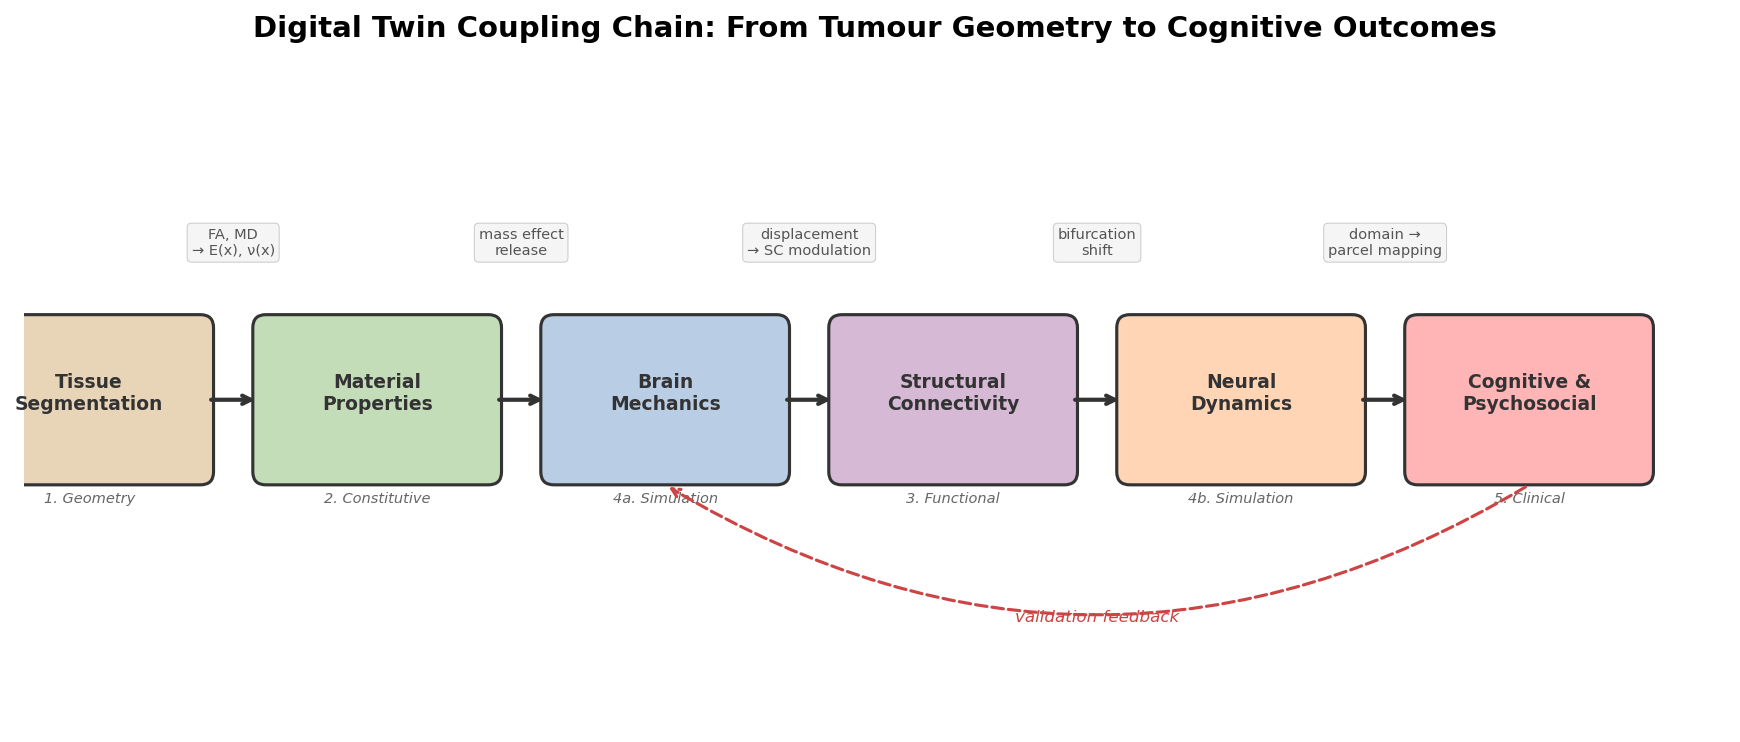

Saved: figures/capstone/figC01_01_coupling_chain.png


In [2]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.set_xlim(-0.5, 12.5)
ax.set_ylim(-1.5, 3.5)
ax.set_aspect('equal')
ax.axis('off')
fig.suptitle('Digital Twin Coupling Chain: From Tumour Geometry to Cognitive Outcomes',
             fontsize=14, fontweight='bold', y=0.98)

boxes = [
    (0.0, 1.0, 'Tissue\nSegmentation', '1. Geometry', '#E8D5B7'),
    (2.2, 1.0, 'Material\nProperties', '2. Constitutive', '#C4DDB9'),
    (4.4, 1.0, 'Brain\nMechanics', '4a. Simulation', '#B9CDE5'),
    (6.6, 1.0, 'Structural\nConnectivity', '3. Functional', '#D5B9D5'),
    (8.8, 1.0, 'Neural\nDynamics', '4b. Simulation', '#FFD5B5'),
    (11.0, 1.0, 'Cognitive &\nPsychosocial', '5. Clinical', '#FFB5B5'),
]

for (x, y, label, sublabel, color) in boxes:
    rect = FancyBboxPatch((x - 0.85, y - 0.55), 1.7, 1.1,
                          boxstyle='round,pad=0.1', facecolor=color,
                          edgecolor='#333333', linewidth=1.5)
    ax.add_patch(rect)
    ax.text(x, y + 0.05, label, ha='center', va='center',
            fontsize=9, fontweight='bold', color='#333333')
    ax.text(x, y - 0.7, sublabel, ha='center', va='top',
            fontsize=7, fontstyle='italic', color='#666666')

for i in range(len(boxes) - 1):
    x1 = boxes[i][0] + 0.9
    x2 = boxes[i+1][0] - 0.9
    ax.annotate('', xy=(x2, 1.0), xytext=(x1, 1.0),
                arrowprops=dict(arrowstyle='->', color='#333333',
                                lw=2, connectionstyle='arc3,rad=0'))

ax.annotate('', xy=(4.4, 0.35), xytext=(11.0, 0.35),
            arrowprops=dict(arrowstyle='->', color='#CC4444',
                            lw=1.5, linestyle='dashed',
                            connectionstyle='arc3,rad=-0.3'))
ax.text(7.7, -0.6, 'validation feedback', ha='center', va='top',
        fontsize=8, fontstyle='italic', color='#CC4444')

coupling_labels = [
    (1.1, 2.2, 'FA, MD\n\u2192 E(x), \u03bd(x)'),
    (3.3, 2.2, 'mass effect\nrelease'),
    (5.5, 2.2, 'displacement\n\u2192 SC modulation'),
    (7.7, 2.2, 'bifurcation\nshift'),
    (9.9, 2.2, 'domain \u2192\nparcel mapping'),
]
for (x, y, label) in coupling_labels:
    ax.text(x, y, label, ha='center', va='center',
            fontsize=7, color='#555555',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#F5F5F5',
                      edgecolor='#CCCCCC', linewidth=0.5))

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC01_01_coupling_chain.png', bbox_inches='tight')
plt.show()
print(f'Saved: {FIG_DIR}/figC01_01_coupling_chain.png')

---
## 5. Data Collected from Multiple Sources

The BTC dataset (Aerts et al., 2022) provides dense multimodal data for
each patient at two timepoints. For PAT16, the data landscape spans
structural, diffusion, and functional MRI, as well as cognitive and
psychosocial assessments.

### Raw data (BIDS-organised)

| Modality | Pre-op | Post-op | Purpose |
|----------|--------|---------|--------|
| T1-weighted MRI | `ses-preop/anat/T1w.nii.gz` | `ses-postop/anat/T1w.nii.gz` | Anatomy, segmentation, geometry |
| DWI (AP + PA) | `ses-preop/dwi/*.nii.gz` | `ses-postop/dwi/*.nii.gz` | Diffusion tensor, tractography, SC |
| rs-fMRI (BOLD) | `ses-preop/func/*bold.nii.gz` | `ses-postop/func/*bold.nii.gz` | Hemodynamics, functional connectivity |
| CANTAB battery | `sessions.tsv` (pre columns) | `sessions.tsv` (post columns) | Cognitive outcomes |
| Psychosocial | STAI, PSWQ, ERQ, UCLA | STAI, PSWQ, ERQ, UCLA | Psychosocial context |

### Derived data (pipeline-computed)

| Derivative | Pipeline | Output |
|-----------|----------|--------|
| Cortical parcellation | FreeSurfer recon-all-clinical | `aparc+aseg.nii.gz` |
| DTI scalar maps | QSIPrep + MRtrix3 | FA, MD, AD, RD maps |
| Structural connectivity | MRtrix3 + SIFT2 | 68x68 SC matrix |
| Functional connectivity | fMRIPrep + compute\_fc.py | 68x68 FC matrix |
| rsHRF parameters | compute\_rshrf.py | FWHM, Height, Time2peak maps |
| Tractography | MRtrix3 | whole\_brain.tck / .trk |
| FEM displacement | FEniCSx (NB07) | displacement magnitude maps |
| Empirical displacement | ANTs SyN | displacement from registration |

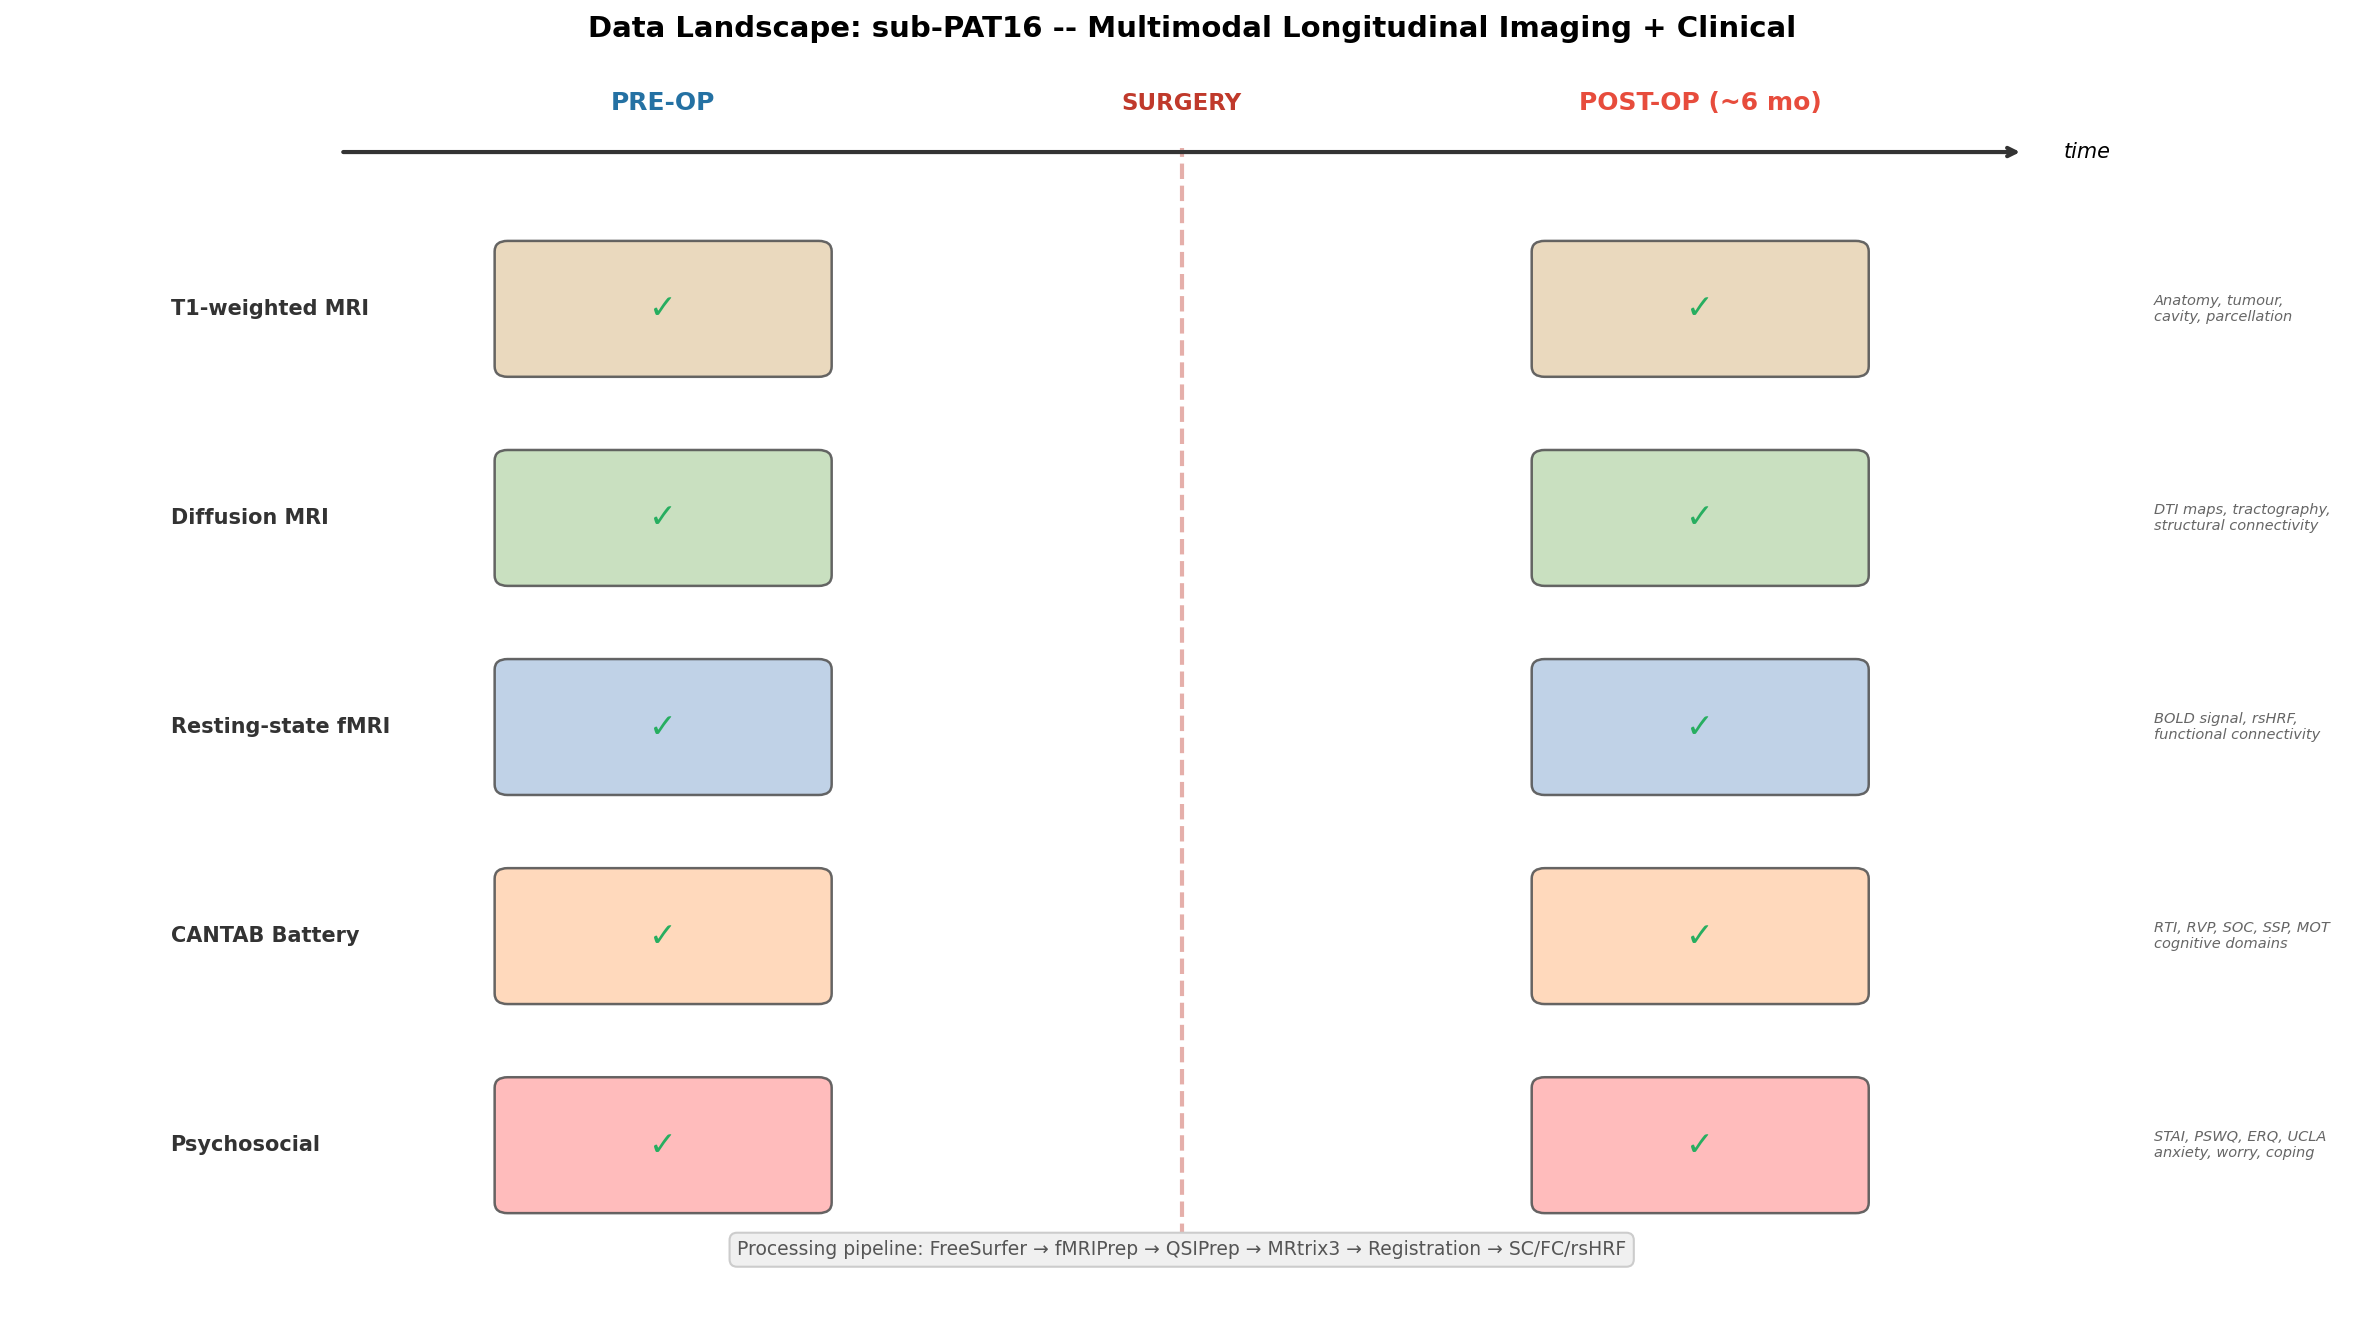

Saved: figures/capstone/figC01_02_data_landscape.png


In [3]:
fig, ax = plt.subplots(figsize=(16, 9))
ax.set_xlim(-1, 17)
ax.set_ylim(-1, 11)
ax.axis('off')
fig.suptitle('Data Landscape: sub-PAT16 -- Multimodal Longitudinal Imaging + Clinical',
             fontsize=14, fontweight='bold', y=0.97)

# Column positions
col_preop = 4.0
col_postop = 12.0
col_mid = 8.0

# Time axis
ax.annotate('', xy=(14.5, 10), xytext=(1.5, 10),
            arrowprops=dict(arrowstyle='->', lw=2, color='#333'))
ax.text(col_preop, 10.4, 'PRE-OP', ha='center', fontsize=12,
        fontweight='bold', color='#2471A3')
ax.text(col_mid, 10.4, 'SURGERY', ha='center', fontsize=11,
        fontweight='bold', color='#C0392B')
ax.text(col_postop, 10.4, 'POST-OP (~6 mo)', ha='center', fontsize=12,
        fontweight='bold', color='#E74C3C')
ax.text(14.8, 10, 'time', fontsize=10, va='center', fontstyle='italic')

# Surgery marker
ax.axvline(col_mid, color='#C0392B', lw=2, ls='--', alpha=0.4, ymin=0.05, ymax=0.92)

modalities = [
    ('T1-weighted MRI',     8.5, '#E8D5B7', 'Anatomy, tumour,\ncavity, parcellation'),
    ('Diffusion MRI',       6.5, '#C4DDB9', 'DTI maps, tractography,\nstructural connectivity'),
    ('Resting-state fMRI',  4.5, '#B9CDE5', 'BOLD signal, rsHRF,\nfunctional connectivity'),
    ('CANTAB Battery',      2.5, '#FFD5B5', 'RTI, RVP, SOC, SSP, MOT\ncognitive domains'),
    ('Psychosocial',        0.5, '#FFB5B5', 'STAI, PSWQ, ERQ, UCLA\nanxiety, worry, coping'),
]

for name, y, color, desc in modalities:
    # Label on left
    ax.text(0.2, y, name, ha='left', va='center', fontsize=10,
            fontweight='bold', color='#333')
    # Pre-op box
    rect = FancyBboxPatch((col_preop - 1.2, y - 0.55), 2.4, 1.1,
                          boxstyle='round,pad=0.1', facecolor=color,
                          edgecolor='#555', lw=1.2, alpha=0.9)
    ax.add_patch(rect)
    ax.text(col_preop, y, '\u2713', ha='center', va='center',
            fontsize=16, color='#27AE60', fontweight='bold')
    # Post-op box
    rect2 = FancyBboxPatch((col_postop - 1.2, y - 0.55), 2.4, 1.1,
                           boxstyle='round,pad=0.1', facecolor=color,
                           edgecolor='#555', lw=1.2, alpha=0.9)
    ax.add_patch(rect2)
    ax.text(col_postop, y, '\u2713', ha='center', va='center',
            fontsize=16, color='#27AE60', fontweight='bold')
    # Description on right
    ax.text(15.5, y, desc, ha='left', va='center', fontsize=7,
            color='#666', fontstyle='italic')

# Processing pipeline annotation
ax.text(col_mid, -0.5,
        'Processing pipeline: FreeSurfer \u2192 fMRIPrep \u2192 QSIPrep \u2192 MRtrix3 \u2192 Registration \u2192 SC/FC/rsHRF',
        ha='center', va='center', fontsize=9, color='#555',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#F0F0F0',
                  edgecolor='#CCC', lw=1))

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC01_02_data_landscape.png', bbox_inches='tight')
plt.show()
print(f'Saved: {FIG_DIR}/figC01_02_data_landscape.png')

---
## 6. BIDS Dataset Structure

The data is organised following the **Brain Imaging Data Structure (BIDS)**
standard, which ensures machine-readable, reproducible data management.
Let us inspect the dataset programmatically.

In [4]:
# Inspect the BIDS dataset
dataset_desc_path = BIDS_ROOT / 'dataset_description.json'
participants_path = BIDS_ROOT / 'participants.tsv'
sessions_path     = BIDS_ROOT / 'sub-PAT16' / 'sub-PAT16_sessions.tsv'

if dataset_desc_path.exists():
    with open(dataset_desc_path) as f:
        ds_desc = json.load(f)
    print('Dataset description:')
    for k, v in ds_desc.items():
        print(f'  {k}: {v}')

print()
if participants_path.exists():
    df_part = pd.read_csv(participants_path, sep='\t')
    print(f'Participants ({len(df_part)}): {list(df_part["participant_id"])}')
    print(df_part.to_string(index=False))

print()
if sessions_path.exists():
    df_ses = pd.read_csv(sessions_path, sep='\t')
    print(f'Sessions for sub-PAT16: {list(df_ses["session_id"])}')
    print(f'Number of variables: {len(df_ses.columns)}')
    print(f'Columns: {list(df_ses.columns)}')

Dataset description:
  Name: BTC_preop_postop_glioma_subset
  BIDSVersion: 1.9.0
  DatasetType: raw
  License: CC0
  Authors: ['Aerts, H', 'Marinazzo, D']
  Acknowledgements: We would like to thank Prof. Dr. Van Roost and Prof. Dr. Eric Achten for their support in recruiting and testing patients at the Ghent University Hospital. We are also grateful to Stephanie Bogaert, Pieter Vandemaele and Ben Jeurissen for their technical assistance in setting up the scanning protocols.
  HowToAcknowledge: This dataset was obtained from the OpenNeuro database. Please cite the original datasets: ds001226 (BTC_preop) and ds002080 (BTC_postop).
  Funding: ['Special Research Funds (BOF) of the University of Ghent (01MR0210 and 01J10715)', 'Interuniversity Attraction Poles Program of the Belgian Federal Government (P7/11)', "European Union's Horizon 2020 Framework Programme for Research and Innovation under the Specific Grant Agreement No. 785907 (Human Brain Project SGA2)"]
  ReferencesAndLinks: ['http

In [5]:
# Enumerate the raw data files per session
subject_dir = BIDS_ROOT / 'sub-PAT16'

for session in ['ses-preop', 'ses-postop']:
    ses_dir = subject_dir / session
    if not ses_dir.exists():
        print(f'{session}: directory not found')
        continue
    print(f'\n{"=" * 60}')
    print(f'  {session}')
    print(f'{"=" * 60}')
    for modality in ['anat', 'dwi', 'func']:
        mod_dir = ses_dir / modality
        if mod_dir.exists():
            files = sorted(mod_dir.glob('*'))
            print(f'  {modality}/ ({len(files)} files)')
            for f in files:
                size_mb = f.stat().st_size / 1e6
                print(f'    {f.name:55s}  {size_mb:7.1f} MB')

# Enumerate derivatives
print(f'\n{"=" * 60}')
print('  BIDS derivatives')
print(f'{"=" * 60}')
for deriv_dir in sorted(DERIV_BIDS.iterdir()):
    if deriv_dir.is_dir():
        n_files = sum(1 for _ in deriv_dir.rglob('*') if _.is_file())
        print(f'  {deriv_dir.name}/  ({n_files} files)')


  ses-preop
  anat/ (3 files)
    .gitkeep                                                     0.0 MB
    sub-PAT16_ses-preop_T1w.json                                 0.0 MB
    sub-PAT16_ses-preop_T1w.nii.gz                               7.7 MB
  dwi/ (9 files)
    .gitkeep                                                     0.0 MB
    sub-PAT16_ses-preop_acq-AP_dwi.bval                          0.0 MB
    sub-PAT16_ses-preop_acq-AP_dwi.bvec                          0.0 MB
    sub-PAT16_ses-preop_acq-AP_dwi.json                          0.0 MB
    sub-PAT16_ses-preop_acq-AP_dwi.nii.gz                       46.7 MB
    sub-PAT16_ses-preop_acq-PA_dwi.bval                          0.0 MB
    sub-PAT16_ses-preop_acq-PA_dwi.bvec                          0.0 MB
    sub-PAT16_ses-preop_acq-PA_dwi.json                          0.0 MB
    sub-PAT16_ses-preop_acq-PA_dwi.nii.gz                        1.1 MB
  func/ (3 files)
    .gitkeep                                                     0.0 M

---
## 7. Processing Pipeline Overview

The raw MRI data is processed through a multi-stage pipeline to produce
the derivatives used throughout the capstone series. All derived data
except for the original images, tumour masks, demographics, and
clinical/neuropsychological data is computed "de novo" from the pipeline.

```
Raw BIDS data
   |
   +-- T1w --> FreeSurfer recon-all-clinical --> aparc+aseg, surfaces
   |                                               |
   +-- DWI --> QSIPrep --> MRtrix3 (CSD, tractography, SIFT2) --> SC
   |                                               |
   +-- BOLD --> fMRIPrep --> confound regression --> FC, rsHRF
   |
   +-- All modalities --> register_to_t1w.sh --> common T1w space
   |                                               |
   +-- Pre/post T1w --> register_longitudinal.sh --> displacement field
   |                                               |
   +-- aparc+aseg --> create_brain_mesh.py --> FE mesh
   |                                               |
   +-- Mesh + DTI + tumour --> FEniCSx (NB07) --> FEM displacement
```

In [6]:
# Show the pipeline derivatives directory structure
print('Pipeline derivatives (project-level):')
print(f'  Location: {DERIV_PROJ}')
print()

if DERIV_PROJ.exists():
    for d in sorted(DERIV_PROJ.iterdir()):
        if d.is_dir():
            n_files = sum(1 for _ in d.rglob('*') if _.is_file())
            print(f'  {d.name:30s}  ({n_files:4d} files)')
else:
    print('  (derivatives directory not found -- run the pipeline first)')

Pipeline derivatives (project-level):
  Location: <REPO_ROOT>/derivatives

  TVB                             (   4 files)
  connectivity                    (  16 files)
  fmriprep                        ( 137 files)
  freesurfer                      ( 785 files)
  meshes                          (   8 files)
  mrtrix_recon                    (  46 files)
  qsiprep                         (  97 files)
  registered_t1w                  (  62 files)
  resseg                          (   1 files)
  rsHRF                           (   6 files)
  tumorsynth                      (  12 files)


---

## 8. Capstone Series Roadmap

This notebook is the first in a series of nine that trace the coupling
chain from data to prediction:

| Notebook | Focus | Key question |
|----------|-------|--------------|
| **NB\_C01** (this) | Concept and data landscape | What is a digital twin and what data do we have? |
| NB\_C02 | Clinical and cognitive data | What do the CANTAB tests measure and how did PAT16 change? |
| NB\_C03 | Structural MRI and segmentation | What does the brain look like before and after surgery? |
| NB\_C04 | Diffusion MRI and tractography | How is white matter organised and how is SC disrupted? |
| NB\_C05 | Resting-state fMRI | How do spontaneous brain dynamics change after surgery? |
| NB\_C06 | Brain mechanics | How does the brain deform when the tumour is removed? |
| NB\_C07 | Neural dynamics | How do mechanics modulate neural oscillations? |
| NB\_C08 | Closing the loop | Does predicted disruption match observed cognitive change? |
| NB\_C09 | Synthesis and perspectives | What are the mathematical challenges ahead? |

---

## References

### Digital twins in engineering

- Grieves M & Vickers J (2017). Digital Twin: Mitigating Unpredictable, Undesirable Emergent Behavior in Complex Systems. In *Transdisciplinary Perspectives on Complex Systems*. Springer. [doi:10.1007/978-3-319-38756-7_4](https://doi.org/10.1007/978-3-319-38756-7_4)
- Kapteyn MG et al. (2021). A probabilistic graphical model foundation for enabling predictive digital twins at scale. *Nature Computational Science* 1:337--347. [doi:10.1038/s43588-021-00069-0](https://doi.org/10.1038/s43588-021-00069-0)
- Hartmann D & Van der Auweraer H (2021). Digital Twins. In *Progress in Industrial Mathematics: Success Stories*. Springer. [doi:10.1007/978-3-030-61844-5_1](https://doi.org/10.1007/978-3-030-61844-5_1)
- Niederer SA et al. (2024). Digital twins in mechanical and aerospace engineering. *Nature Computational Science* 4:178--183. [doi:10.1038/s43588-024-00613-8](https://doi.org/10.1038/s43588-024-00613-8)
- Singh M et al. (2025). Digital twins: Recent advances and future directions in engineering fields. *Results in Engineering*. [doi:10.1016/j.rineng.2025.104233](https://doi.org/10.1016/j.rineng.2025.104233)

### Digital twins in medicine and biology

- Laubenbacher R et al. (2024). Digital twins in medicine. *Nature Computational Science* 4:184--191. [doi:10.1038/s43588-024-00607-6](https://doi.org/10.1038/s43588-024-00607-6)
- Elkefi S & Asan O (2024). Concepts and applications of digital twins in healthcare and medicine. *Patterns* 5(8):101028. [doi:10.1016/j.patter.2024.101028](https://doi.org/10.1016/j.patter.2024.101028)
- Drummond D et al. (2025). Medical Digital Twin: A review on technical principles and clinical applications. *Journal of Medical Internet Research*. [doi:10.2196/67068](https://doi.org/10.2196/67068)
- Babei A et al. (2025). Survey and perspective on verification, validation, and uncertainty quantification of digital twins for precision medicine. *npj Digital Medicine* 8:89. [doi:10.1038/s41746-025-01447-y](https://doi.org/10.1038/s41746-025-01447-y)

### Digital twins in neuroscience, brain, and cognition

- Aerts H et al. (2018). Modeling Brain Dynamics in Brain Tumor Patients Using the Virtual Brain. *eNeuro* 5(3). [doi:10.1523/ENEURO.0083-18.2018](https://doi.org/10.1523/ENEURO.0083-18.2018)
- Aerts H et al. (2022). Pre- and post-surgery brain tumor multimodal MRI data. *Scientific Data* 9:676. [doi:10.1038/s41597-022-01806-4](https://doi.org/10.1038/s41597-022-01806-4)
- Vohryzek J et al. (2024). The digital twin in neuroscience: from theory to tailored therapy. *Frontiers in Neuroscience* 18:1454856. [doi:10.3389/fnins.2024.1454856](https://doi.org/10.3389/fnins.2024.1454856)
- Lu Y et al. (2025). Ten years of the digital twin brain: Perspectives and challenges. *Europhysics Letters* 149:42001. [doi:10.1209/0295-5075/adb3c9](https://doi.org/10.1209/0295-5075/adb3c9)
- Ponce-Alvarez A et al. (2025). Digital twin brain simulator for real-time consciousness monitoring and virtual intervention. *npj Digital Medicine* 8:82. [doi:10.1038/s41746-025-01444-1](https://doi.org/10.1038/s41746-025-01444-1)